In [1]:

import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor

# 1. Cargar datos
df = pd.read_csv(
    "../data/processed/gatun_monthly.csv",
    parse_dates=["date"],
    index_col="date"
).sort_index()

# 2. Normalizar fechas al inicio de cada mes
rain = df["rainfall_mm"].copy()
rain.index = rain.index.to_period("M").to_timestamp()

# Verificar que no existan meses duplicados
if rain.index.has_duplicates:
    raise ValueError("Hay meses duplicados en el archivo.")

# Crear serie mensual continua
rain = rain.asfreq("MS")

# Verificar datos faltantes
if rain.isna().any():
    missing = rain[rain.isna()].index.strftime("%Y-%m").tolist()
    raise ValueError(f"Hay meses sin datos: {missing}")

print("Primera fecha:", rain.index.min())
print("Última fecha:", rain.index.max())
print("Meses disponibles:", len(rain))

# 3. Crear variables históricas
data = pd.DataFrame({"rainfall_mm": rain})

for lag in [1, 2, 3, 12]:
    data[f"lag_{lag}"] = data["rainfall_mm"].shift(lag)

data["month_sin"] = np.sin(
    2 * np.pi * data.index.month / 12
)
data["month_cos"] = np.cos(
    2 * np.pi * data.index.month / 12
)

features = [
    "lag_1", "lag_2", "lag_3", "lag_12",
    "month_sin", "month_cos"
]

training = data.dropna()

if training.empty:
    raise ValueError("No hay suficientes datos para entrenar.")

# 4. Entrenar modelo
model = RandomForestRegressor(
    n_estimators=300,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

model.fit(
    training[features],
    training["rainfall_mm"]
)

# 5. Crear fechas futuras automáticamente
last_date = rain.index.max()

future_dates = pd.date_range(
    start=last_date + pd.DateOffset(months=1),
    periods=12,
    freq="MS"
)

# 6. Pronóstico recursivo
history = rain.copy()
predictions = []

for date in future_dates:
    month = date.month

    row = pd.DataFrame([{
        "lag_1": history.loc[date - pd.DateOffset(months=1)],
        "lag_2": history.loc[date - pd.DateOffset(months=2)],
        "lag_3": history.loc[date - pd.DateOffset(months=3)],
        "lag_12": history.loc[date - pd.DateOffset(months=12)],
        "month_sin": np.sin(2 * np.pi * month / 12),
        "month_cos": np.cos(2 * np.pi * month / 12)
    }])

    forecast = max(
        0,
        model.predict(row[features])[0]
    )

    history.loc[date] = forecast

    predictions.append({
        "date": date,
        "forecast_mm": round(forecast, 2)
    })

# 7. Resultados
forecast_df = pd.DataFrame(predictions)

print("\nPronóstico mensual de precipitaciones:")
print(forecast_df.to_string(index=False))


Primera fecha: 1981-01-01 00:00:00
Última fecha: 2026-09-01 00:00:00
Meses disponibles: 549

Pronóstico mensual de precipitaciones:
      date  forecast_mm
2026-10-01       220.95
2026-11-01       247.17
2026-12-01       106.20
2027-01-01        87.85
2027-02-01       147.39
2027-03-01        46.52
2027-04-01        85.81
2027-05-01       247.61
2027-06-01       226.47
2027-07-01       230.41
2027-08-01       235.62
2027-09-01       262.23


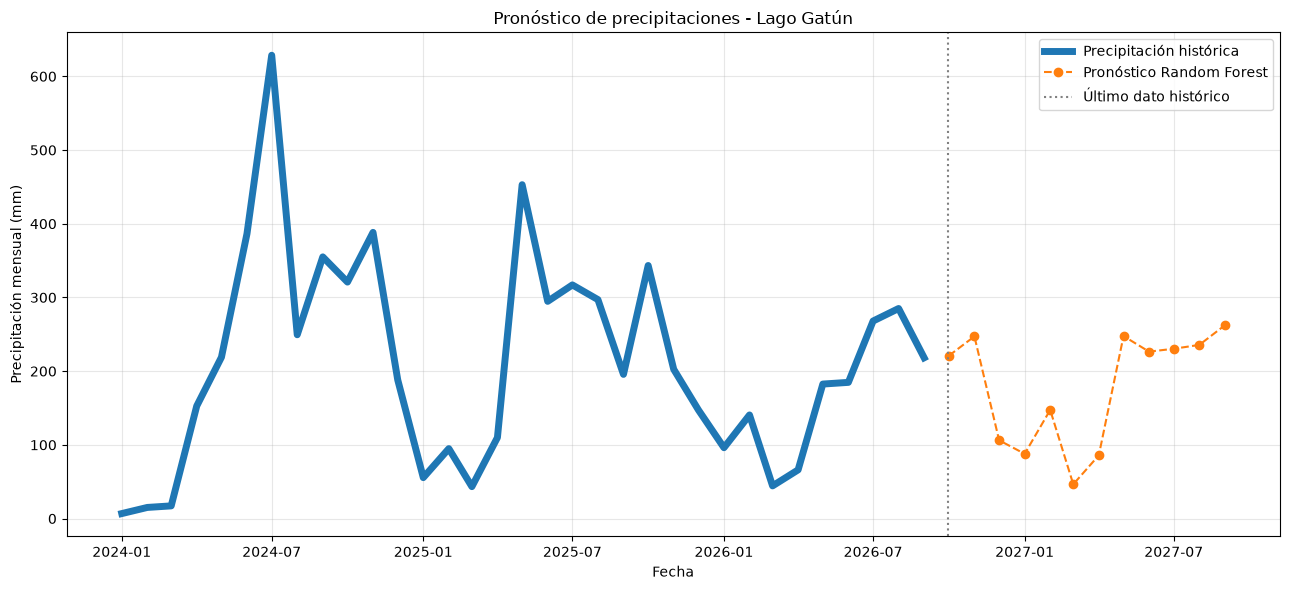

In [4]:

import matplotlib.pyplot as plt
from pathlib import Path

Path("../figures").mkdir(exist_ok=True)

historical = rain.loc["2024-01-01":]

plt.figure(figsize=(13, 6))

plt.plot(
    historical.index,
    historical.values,
    label="Precipitación histórica",
    linewidth=5
)

plt.plot(
    forecast_df["date"],
    forecast_df["forecast_mm"],
    marker="o",
    linestyle="--",
    label="Pronóstico Random Forest"
)

plt.axvline(
    pd.Timestamp("2026-09-30"),
    color="gray",
    linestyle=":",
    label="Último dato histórico"
)

plt.title("Pronóstico de precipitaciones - Lago Gatún")
plt.xlabel("Fecha")
plt.ylabel("Precipitación mensual (mm)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../figures/rainfall_forecast.png",
    dpi=300
)

plt.show()

In [18]:

from pathlib import Path

Path("../data/processed").mkdir(
    parents=True, exist_ok=True
)

forecast_df.to_csv(
    "../data/processed/forecast_2026_2027.csv",
    index=False
)

print("Pronóstico guardado correctamente.")


Pronóstico guardado correctamente.


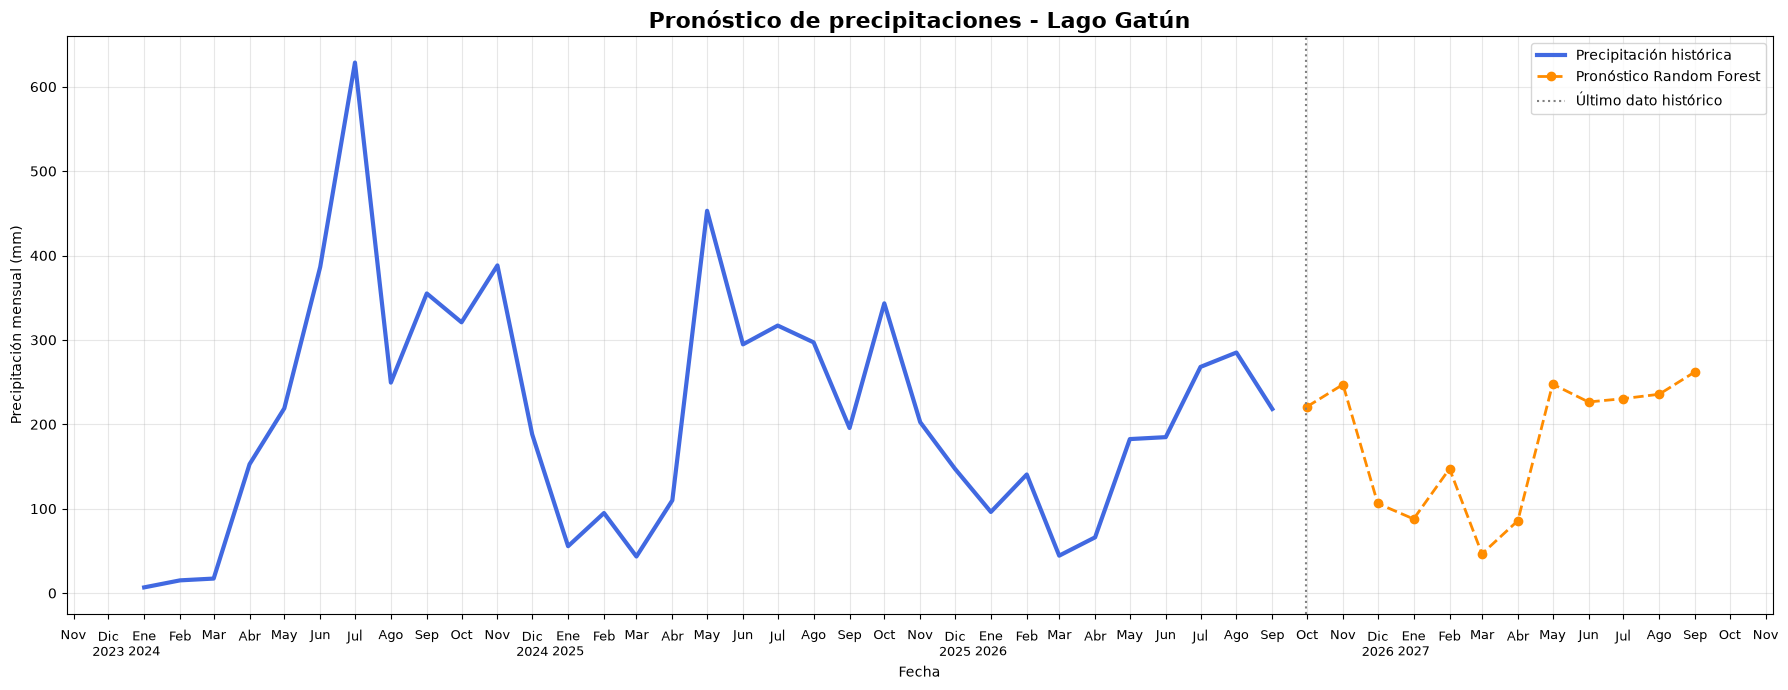

In [6]:

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd
from matplotlib.ticker import FuncFormatter
from pathlib import Path

Path("../figures").mkdir(exist_ok=True)

historical = rain.loc["2024-01-01":]

fig, ax = plt.subplots(figsize=(18, 7))

# Precipitación histórica
ax.plot(
    historical.index,
    historical.values,
    label="Precipitación histórica",
    linewidth=3,
    color="royalblue"
)

# Pronóstico Random Forest
ax.plot(
    forecast_df["date"],
    forecast_df["forecast_mm"],
    marker="o",
    linestyle="--",
    linewidth=2,
    color="darkorange",
    label="Pronóstico Random Forest"
)

# Línea divisoria histórico / pronóstico
ax.axvline(
    pd.Timestamp("2026-09-30"),
    color="gray",
    linestyle=":",
    label="Último dato histórico"
)

# Mostrar todos los meses
ax.xaxis.set_major_locator(
    mdates.MonthLocator(interval=1)
)

# Formato personalizado para los meses
meses = [
    "Ene", "Feb", "Mar", "Abr",
    "May", "Jun", "Jul", "Ago",
    "Sep", "Oct", "Nov", "Dic"
]

def formato_mes(x, pos):
    fecha = mdates.num2date(x)
    mes = meses[fecha.month - 1]

    if fecha.month in [1, 12]:
        return f"{mes}\n{fecha.year}"

    return mes

ax.xaxis.set_major_formatter(
    FuncFormatter(formato_mes)
)

# Configuración visual
ax.tick_params(
    axis="x",
    labelsize=9,
    rotation=0,
    pad=8
)

ax.set_title(
    "Pronóstico de precipitaciones - Lago Gatún",
    fontsize=16,
    fontweight="bold"
)

ax.set_xlabel("Fecha")
ax.set_ylabel("Precipitación mensual (mm)")

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()

# Guardar gráfico
plt.savefig(
    "../figures/rainfall_forecast.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
